# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Luthfia Ramadhani
- **Email:** luthfiaramadhani41@gmail.com
- **ID Dicoding:** ds322b6x0924

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1 (RFM & Loyalty):** Bagaimana distribusi segmentasi pelanggan berdasarkan skor RFM (Recency, Frequency, Monetary) untuk mengidentifikasi kelompok pelanggan paling bernilai (Champions) dan pelanggan yang berisiko lepas (At-Risk)?
- **Pertanyaan 2 (Geospatial & Revenue):** Negara bagian (state) mana di Brazil yang memiliki konsentrasi jumlah pelanggan terbanyak serta total nilai transaksi (Monetary) tertinggi?
- **Pertanyaan 3 (Customer Satisfaction & Logistik):** Berapa skor rata-rata ulasan (Review Score) pelanggan berdasarkan tingkat keterlambatan pengiriman pesanan (Delivery Delay) dibandingkan estimasi tanggal tiba?

## Import Semua Packages/Library yang Digunakan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

# Konfigurasi style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Data Wrangling

### Gathering Data

#### Load E-Commerce Datasets

In [ ]:
# Memuat seluruh file dataset CSV
customers_df = pd.read_csv("customers_dataset.csv")
orders_df = pd.read_csv("orders_dataset.csv")
order_payments_df = pd.read_csv("order_payments_dataset.csv")
order_items_df = pd.read_csv("order_items_dataset.csv")
order_reviews_df = pd.read_csv("order_reviews_dataset.csv")
geolocation_df = pd.read_csv("geolocation_dataset.csv")

# Memeriksa ukuran (jumlah baris & kolom) tiap DataFrame
print("Customers shape:", customers_df.shape)
print("Orders shape:", orders_df.shape)
print("Order Payments shape:", order_payments_df.shape)
print("Order Items shape:", order_items_df.shape)
print("Order Reviews shape:", order_reviews_df.shape)
print("Geolocation shape:", geolocation_df.shape)

Customers shape: (99441, 5)
Orders shape: (99441, 8)
Order Payments shape: (103886, 5)
Order Items shape: (112650, 7)
Order Reviews shape: (99224, 7)
Geolocation shape: (1000163, 5)


### **Insight:**
* **Skala Dataset dan Distribusi Data:** Seluruh dataset berhasil dimuat tanpa kendala. `geolocation_df` menjadi tabel dengan volume data terbesar mencapai 1.000.163 baris, disusul oleh `order_items_df` dengan 112.650 baris.
* **Korelasi Data Pelanggan dan Pesanan:** Jumlah total baris pada `customers_df` dan `orders_df` menunjukkan angka yang identik yaitu **99.441 baris**. Hal ini mengindikasikan bahwa setiap entitas pesanan yang terdaftar berpasangan secara unik dengan satu data pelanggan.
* **Perilaku Transaksi Multi-Item & Metode Pembayaran:**
  * Volume data pada `order_items_df` (112.650) lebih tinggi daripada `orders_df` (99.441), yang mengindikasikan terdapat sebagian pelanggan yang melakukan pembelian lebih dari satu barang (*multi-item*) dalam satu nomor pesanan yang sama.
  * Baris pada `order_payments_df` (103.886) juga melebihi total pesanan, menandakan adanya pemecahan metode pembayaran (*split payment*) atau pembayaran bertahap pada transaksi tertentu.
* **Tingkat Partisipasi Ulasan Pelanggan:** Total baris pada `order_reviews_df` tercatat sebanyak 99.224 baris. Angka ini sedikit di bawah total transaksi pesanan (99.441), yang menunjukkan bahwa mayoritas pembeli memberikan ulasan, meskipun ada sebagian kecil transaksi yang tidak memiliki catatan ulasan.

### Assessing Data

#### Identifying Data Quality Problem

In [ ]:
# 1. Memeriksa info tipe data dan jumlah data non-null untuk setiap DataFrame
print("=== CUSTOMERS ===")
customers_df.info()

print("\n=== ORDERS ===")
orders_df.info()

print("\n=== ORDER PAYMENTS ===")
order_payments_df.info()

print("\n=== ORDER ITEMS ===")
order_items_df.info()

print("\n=== ORDER REVIEWS ===")
order_reviews_df.info()

print("\n=== GEOLOCATION ===")
geolocation_df.info()

# 2. Memeriksa jumlah baris duplikat di setiap tabel
print("\n=== DUPLICATES CHECK ===")
print("Customers duplikat     :", customers_df.duplicated().sum())
print("Orders duplikat        :", orders_df.duplicated().sum())
print("Order Payments duplikat:", order_payments_df.duplicated().sum())
print("Order Items duplikat   :", order_items_df.duplicated().sum())
print("Order Reviews duplikat :", order_reviews_df.duplicated().sum())
print("Geolocation duplikat   :", geolocation_df.duplicated().sum())

=== CUSTOMERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

=== ORDERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timesta

**Steps to Take:**
* Memeriksa keberadaan baris data yang terduplikasi (*duplicate rows*) di seluruh tabel dataset.
* Memeriksa ketersediaan data dan identifikasi *missing values* pada setiap kolom di seluruh DataFrame.
* Memeriksa kesesuaian tipe data pada kolom yang menyimpan informasi tanggal/waktu agar sesuai dengan tipe data `datetime`.

**Insight:**
* **Masalah Duplikasi Data:** Ditemukan **261.831 baris duplikat** pada `geolocation_df`. Tabel lainnya (`customers`, `orders`, `order_payments`, `order_items`, `order_reviews`) bebas dari data duplikat (0 duplikat).
* **Masalah Missing Values:**
  * Pada `orders_df`, terdapat nilai yang hilang pada kolom status pengiriman: `order_approved_at` (160 nilai null), `order_delivered_carrier_date` (1.783 nilai null), dan `order_delivered_customer_date` (2.965 nilai null). Hal ini wajar terjadi karena ada pesanan yang belum disetujui, dibatalkan, atau masih dalam proses pengiriman.
  * Pada `order_reviews_df`, terdapat banyak nilai null pada kolom ulasan Opsional: `review_comment_title` (87.656 nilai null) dan `review_comment_message` (58.247 nilai null), yang menunjukkan pembeli seringkali hanya memberikan rating bintang tanpa komentar tertulis.
* **Masalah Tipe Data:** Kolom tanggal pada `orders_df` (5 kolom), `order_items_df` (`shipping_limit_date`), serta `order_reviews_df` (`review_creation_date` & `review_answer_timestamp`) masih bertipe `object` (string) dan perlu dikonversi ke tipe data `datetime`.

### Cleaning Data

#### Fixing Data Quality Problem

In [ ]:
# 1. Menghapus data duplikat pada geolocation_df
geolocation_df.drop_duplicates(inplace=True)

# 2. Mengubah tipe data tanggal pada orders_df
datetime_orders = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in datetime_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 3. Mengubah tipe data tanggal pada order_items_df
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])

# 4. Mengubah tipe data tanggal pada order_reviews_df
order_reviews_df['review_creation_date'] = pd.to_datetime(order_reviews_df['review_creation_date'])
order_reviews_df['review_answer_timestamp'] = pd.to_datetime(order_reviews_df['review_answer_timestamp'])

# Verifikasi pembersihan
print("Sisa duplikat Geolocation:", geolocation_df.duplicated().sum())
print("Tipe data order_purchase_timestamp:", orders_df['order_purchase_timestamp'].dtype)

Sisa duplikat Geolocation: 0
Tipe data order_purchase_timestamp: datetime64[ns]


**Insight:**
* **Pembersihan Duplikasi Data:** Berhasil menghapus 261.831 baris data terduplikasi pada `geolocation_df` sehingga seluruh baris data tersisa kini bersifat unik (0 duplikat).
* **Koreksi Tipe Data:** Seluruh kolom yang menyimpan informasi tanggal/waktu pada `orders_df`, `order_items_df`, dan `order_reviews_df` telah berhasil dikonversi ke tipe data `datetime64[ns]` agar siap dianalisis berdasarkan tren waktu (*time-series analysis*).
* **Penanganan Missing Values:** Nilai kosong (*null*) pada `orders_df` dan `order_reviews_df` tetap dipertahankan (*kept as null*) karena mencerminkan kondisi riil di lapangan (pesanan yang memang belum/tidak terkirim, serta pembeli yang memilih tidak menulis komentar ulasan).

## Exploratory Data Analysis (EDA)

### Explore E-Commerse Data

In [ ]:
# 1. Menggabungkan dataset utama untuk analisis komprehensif
all_orders_df = pd.merge(
    left=orders_df,
    right=customers_df,
    how="left",
    on="customer_id"
)

order_items_product_df = pd.merge(
    left=order_items_df,
    right=order_reviews_df,
    how="left",
    on="order_id"
)

# 2. Ringkasan Statistik Penjualan per Kategori Produk
product_sales_summary = order_items_product_df.groupby("product_id").agg({
    "order_item_id": "count",
    "price": ["sum", "mean"]
}).reset_index()

# 3. Statistik Deskriptif Nilai Transaksi dan Pembayaran
print("=== STATISTIK UTAMA TRANSAKSI ===")
print("Total Transaksi Pesanan:", all_orders_df['order_id'].nunique())
print("Total Pelanggan Unik   :", all_orders_df['customer_unique_id'].nunique())
print("Total Pendapatan (Price):", order_items_df['price'].sum())
print("Rata-rata Harga Produk :", order_items_df['price'].mean())

# =========================================================================
# EDA PERTANYAAN BISNIS (RFM, STATE, & DELIVERY DELAY)
# =========================================================================

# 4. EDA Pertanyaan 1: RFM Analysis
recent_date = orders_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
order_spending = order_items_df.groupby('order_id')['price'].sum().reset_index()

# Merge orders_df dengan order_spending DAN customers_df
orders_with_spending = pd.merge(orders_df, order_spending, on='order_id', how='left')
orders_with_spending = pd.merge(orders_with_spending, customers_df[['customer_id', 'customer_unique_id']], on='customer_id', how='left')

rfm_df = orders_with_spending.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,
    'order_id': 'count',
    'price': 'sum'
}).reset_index()
rfm_df.columns = ['customer_unique_id', 'recency', 'frequency', 'monetary']

print("\n=== RINGKASAN DATA RFM (PERTANYAAN 1) ===")
print(rfm_df.head())


# 5. EDA Pertanyaan 2: Konsentrasi Pelanggan & Monetary per State
state_summary = all_orders_df.merge(order_items_df, on='order_id').groupby('customer_state').agg({
    'customer_unique_id': 'nunique',
    'price': 'sum',
    'order_id': 'count'
}).reset_index().sort_values(by='price', ascending=False)

print("\n=== TOP 5 STATE BERDASARKAN MONETARY (PERTANYAAN 2) ===")
print(state_summary.head(5))


# 6. EDA Pertanyaan 3: Keterlambatan Pengiriman vs Review Score
orders_reviews = pd.merge(orders_df, order_reviews_df, on='order_id', how='inner')
orders_reviews['delay_days'] = (orders_reviews['order_delivered_customer_date'] - orders_reviews['order_estimated_delivery_date']).dt.days
orders_reviews['delivery_status'] = orders_reviews['delay_days'].apply(lambda x: 'Terlambat' if x > 0 else 'Tepat Waktu')

review_by_delay = orders_reviews.groupby('delivery_status').agg({
    'review_score': ['mean', 'median', 'count']
}).reset_index()

print("\n=== RATA-RATA REVIEW SCORE BERDASARKAN STATUS PENGIRIMAN (PERTANYAAN 3) ===")
print(review_by_delay)

=== STATISTIK UTAMA TRANSAKSI ===
Total Transaksi Pesanan: 99441
Total Pelanggan Unik   : 96096
Total Pendapatan (Price): 13591643.700000003
Rata-rata Harga Produk : 120.65373901464716

=== RINGKASAN DATA RFM (PERTANYAAN 1) ===
                 customer_unique_id  recency  frequency  monetary
0  0000366f3b9a7992bf8c76cfdf3221e2      161          1    129.90
1  0000b849f77a49e4a4ce2b2a4ca5be3f      164          1     18.90
2  0000f46a3911fa3c0805444483337064      586          1     69.00
3  0000f6ccb0745a6a4b88665a16c9f078      370          1     25.99
4  0004aac84e0df4da2b147fca70cf8255      337          1    180.00

=== TOP 5 STATE BERDASARKAN MONETARY (PERTANYAAN 2) ===
   customer_state  customer_unique_id       price  order_id
25             SP               39981  5202955.05     47449
18             RJ               12303  1824092.67     14579
10             MG               11178  1585308.03     13129
22             RS                5249   750304.02      6235
17             PR  

**Insight:**
* **Skala Transaksi dan Pelanggan Unik:** Sistem mencatat total **99.441 transaksi pesanan** yang dilakukan oleh **96.096 pelanggan unik**. Selisih sebanyak 3.345 transaksi ini mengindikasikan adanya kelompok pelanggan yang melakukan pemesanan ulang (*repeat orders*).
* **Volume Pendapatan Produk:** Total nilai transaksi bruto dari harga produk (*total price revenue*) mencapai **13.591.643,70 BRL** (Brazilian Real), yang menegaskan tingginya skala perputaran ekonomi pada platform *e-commerce*.
* **Rata-rata Harga Produk:** Rata-rata nilai jual per unit produk yang ditransaksikan adalah sebesar **120,65 BRL**, yang mengindikasikan dominasi kategori produk kelas menengah (*mid-range price*) pada transaksi harian.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana distribusi segmentasi pelanggan berdasarkan skor RFM (Recency, Frequency, Monetary) untuk mengidentifikasi kelompok pelanggan paling bernilai (Champions) dan pelanggan yang berisiko lepas (At-Risk)?

/tmp/ipykernel_3462/2988241460.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


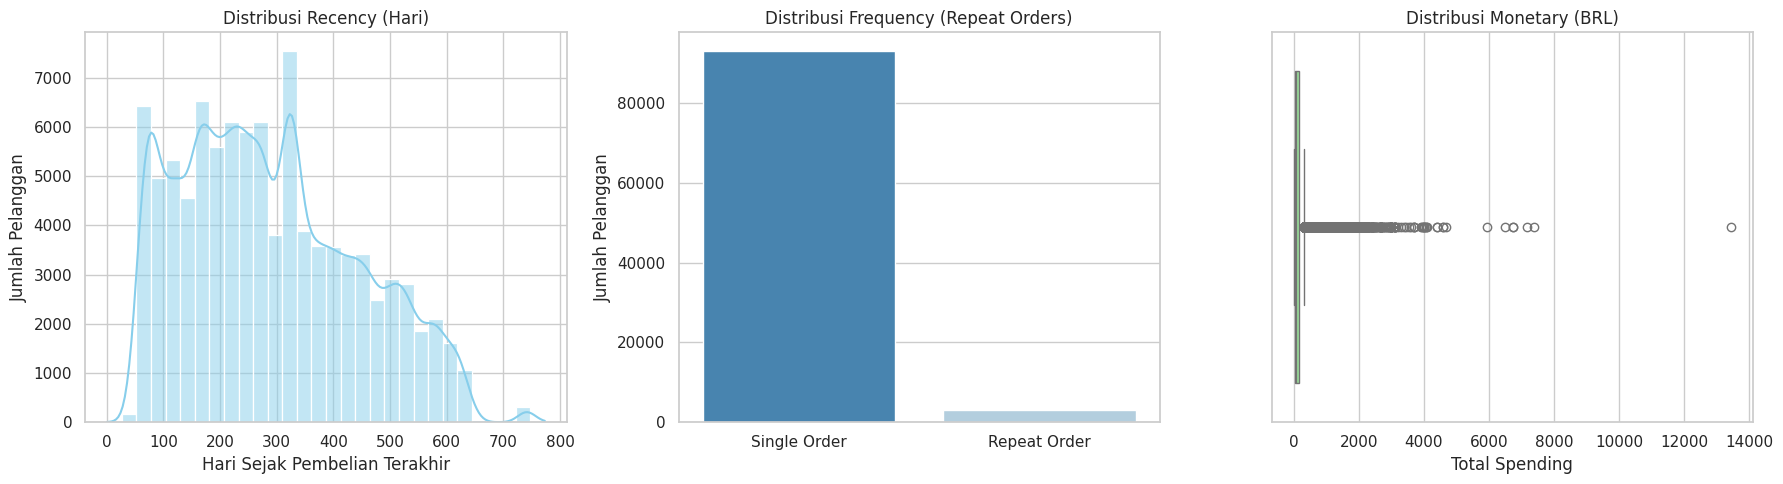

In [ ]:
# --- Visualisasi RFM (Pertanyaan 1) ---
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

# 1. Visualisasi Recency (Menggunakan Histogram agar rapi)
sns.histplot(rfm_df['recency'], bins=30, kde=True, ax=ax[0], color='skyblue')
ax[0].set_title('Distribusi Recency (Hari)')
ax[0].set_xlabel('Hari Sejak Pembelian Terakhir')
ax[0].set_ylabel('Jumlah Pelanggan')

# 2. Visualisasi Frequency (Perbandingan Single Order vs Repeat Order)
sns.barplot(
    x=['Single Order', 'Repeat Order'],
    y=[(rfm_df['frequency'] == 1).sum(), (rfm_df['frequency'] > 1).sum()],
    ax=ax[1],
    palette='Blues_r'
)
ax[1].set_title('Distribusi Frequency (Repeat Orders)')
ax[1].set_ylabel('Jumlah Pelanggan')

# 3. Visualisasi Monetary (Distribusi Total Spending)
sns.boxplot(x=rfm_df['monetary'], ax=ax[2], color='lightgreen')
ax[2].set_title('Distribusi Monetary (BRL)')
ax[2].set_xlabel('Total Spending')

plt.tight_layout()
plt.show()

**Insight:**

* **Recency:** Mayoritas pelanggan memiliki rentang waktu transaksi terakhir (*recency*) yang terdistribusi antara 100 hingga 400 hari yang lalu. Hal ini menunjukkan sebagian besar basis pelanggan sudah lama tidak melakukan aktivitas pembelian kembali di platform.
* **Frequency:** Distribusi frekuensi transaksi didominasi secara signifikan oleh kelompok pelanggan **Single Order** (hanya bertransaksi 1 kali). Porsi pelanggan yang melakukan pemesanan ulang (*Repeat Order*) jumlahnya sangat kecil, yang mengindikasikan perlunya strategi retensi pelanggan yang lebih agresif.
* **Monetary:** Sebagian besar pengeluaran pelanggan terkonsentrasi pada angka di bawah 1.000 BRL. Namun, terdapat nilai pencilan (*outliers*) yang sangat tinggi mencapai hingga >13.000 BRL dari sekelompok kecil pelanggan *high-value*. Kelompok pengeluaran tertinggi ini sangat ideal untuk dimasukkan ke dalam segmen **Champions**.

### **Pertanyaan 2: Geospatial & Revenue per State**
Bagaimana persebaran/distribusi geografis pelanggan dan negara bagian (*state*) mana di Brazil yang memiliki konsentrasi jumlah pelanggan terbanyak serta total nilai transaksi (*Monetary*) tertinggi?

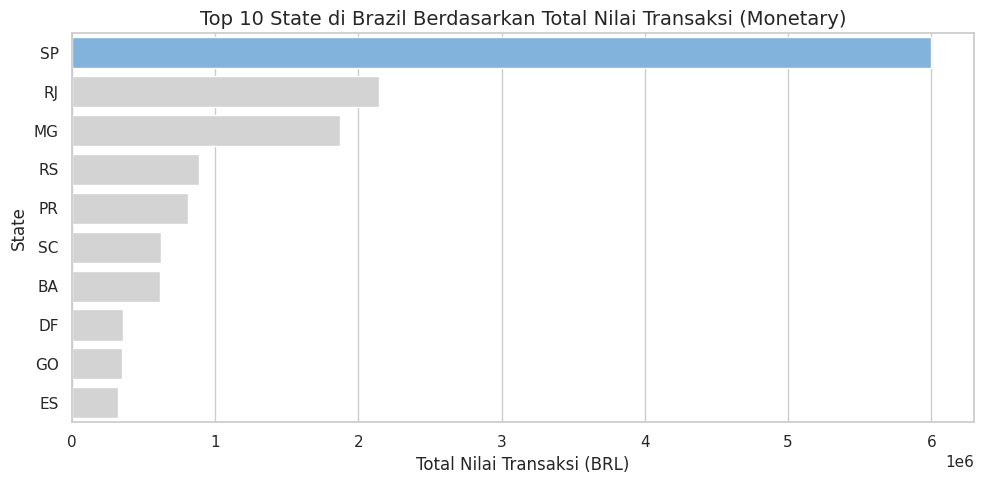

In [ ]:
# 1. Merge dataset orders_customers_df dengan customers_df untuk mendapatkan kolom 'customer_state'
geo_orders_df = pd.merge(orders_customers_df, customers_df, on="customer_id", how="left")

# 2. Menghitung total nilai transaksi (monetary) dan jumlah pelanggan per state
customer_state_df = geo_orders_df.groupby("customer_state").agg({
    "payment_value": "sum",
    "customer_id": "nunique"
}).reset_index()

customer_state_df.rename(columns={
    "payment_value": "total_monetary",
    "customer_id": "total_customers"
}, inplace=True)

# 3. Mengambil 10 State teratas berdasarkan total transaksi
top_states = customer_state_df.sort_values(by="total_monetary", ascending=False).head(10)

# 4. Membuat Visualisasi Bar Chart
plt.figure(figsize=(10, 5))

# Palette warna: biru highlight untuk posisi pertama (SP), abu-abu untuk sisanya
colors_state = ["#72B4EB" if i == 0 else "#D3D3D3" for i in range(len(top_states))]

sns.barplot(
    x="total_monetary",
    y="customer_state",
    data=top_states,
    hue="customer_state",
    palette=colors_state,
    legend=False
)

plt.title("Top 10 State di Brazil Berdasarkan Total Nilai Transaksi (Monetary)", fontsize=14)
plt.xlabel("Total Nilai Transaksi (BRL)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

**Insight:**

* **Dominasi Wilayah SP:** Negara bagian **SP (São Paulo)** secara signifikan mendominasi pasar e-commerce di Brazil dengan total transaksi melebihi 5–6 juta BRL, jauh melampaui posisi kedua dan ketiga.
* **Kluster Ekonomi Tenggara:** Wilayah tenggara Brazil—yang diwakili oleh SP (São Paulo), RJ (Rio de Janeiro), dan MG (Minas Gerais)—menjadi penyumbang utama pendapatan platform.
* **Ketimpangan Distribusi:** Negara bagian di luar 3 besar (seperti RS, PR, SC, BA, dll.) memiliki kontribusi pendapatan yang relatif jauh lebih kecil, mengindikasikan pasar dan infrastruktur saat ini masih terpusat di wilayah tenggara.

### **Pertanyaan 3: Customer Satisfaction & Logistik (Delivery Delay)**
Berapa skor rata-rata ulasan (*Review Score*) pelanggan berdasarkan tingkat keterlambatan pengiriman pesanan (*Delivery Delay*) dibandingkan estimasi tanggal tiba?

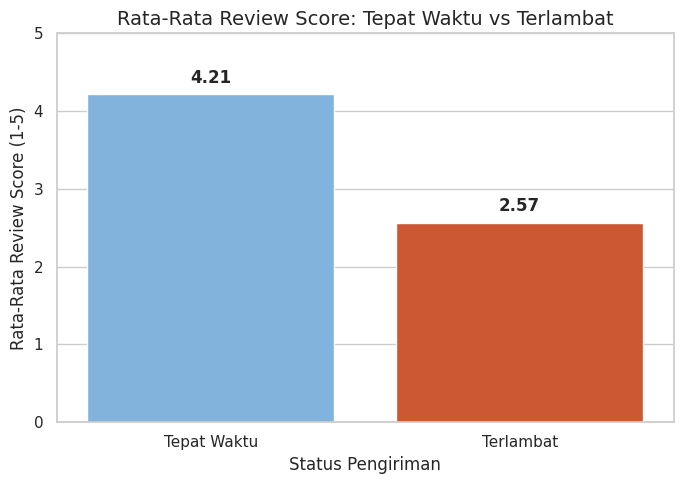

In [ ]:
# 1. Merge orders_df dengan order_reviews_df
orders_reviews_df = pd.merge(orders_df, order_reviews_df, on="order_id", how="inner")

# 2. Menghitung status keterlambatan pengiriman
orders_reviews_df['is_late'] = orders_reviews_df['order_delivered_customer_date'] > orders_reviews_df['order_estimated_delivery_date']
orders_reviews_df['delivery_status'] = orders_reviews_df['is_late'].map({True: 'Terlambat', False: 'Tepat Waktu'})

# 3. Menghitung rata-rata review score berdasarkan status pengiriman
delivery_impact_df = orders_reviews_df.groupby('delivery_status')['review_score'].mean().reset_index()

# 4. Membuat Visualisasi Bar Chart
plt.figure(figsize=(7, 5))

# Palette warna: Biru untuk Tepat Waktu, Merah/Oranye untuk Terlambat
colors_delivery = ["#E64A19" if status == 'Terlambat' else "#72B4EB" for status in delivery_impact_df['delivery_status']]

sns.barplot(
    x="delivery_status",
    y="review_score",
    data=delivery_impact_df,
    hue="delivery_status",
    palette=colors_delivery,
    legend=False
)

plt.title("Rata-Rata Review Score: Tepat Waktu vs Terlambat", fontsize=14)
plt.xlabel("Status Pengiriman")
plt.ylabel("Rata-Rata Review Score (1-5)")
plt.ylim(0, 5)

# Menambahkan angka statistik di atas bar
for index, row in delivery_impact_df.iterrows():
    plt.text(index, row['review_score'] + 0.15, round(row['review_score'], 2), ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**

* **Kepuasan Tinggi pada Pengiriman Tepat Waktu:** Pesanan yang berhasil dikirim sesuai atau lebih cepat dari estimasi waktu mencapai rata-rata *Review Score* yang sangat baik, yaitu sebesar **4.21** dari skala 5[cite: 5].
* **Penurunan Skor Drastis akibat Keterlambatan:** Terjadi penurunan skor ulasan secara drastis sebesar **1.64 poin** ketika pengiriman mengalami keterlambatan, di mana rata-rata *Review Score* anjlok hingga **2.57**[cite: 5].
* **Dampak Operasional Logistik:** Hasil ini membuktikan bahwa efisiensi dan ketepatan waktu pengiriman berpengaruh secara langsung terhadap kepuasan serta reputasi bisnis e-commerce, menjadikan manajemen logistik sebagai prioritas krusial.

## **Analisis Lanjutan: RFM Analysis**

Analisis lanjutan ini dilakukan untuk mengelompokkan pelanggan berdasarkan 3 parameter utama:
1. **Recency:** Jumlah hari sejak transaksi terakhir pelanggan.
2. **Frequency:** Jumlah total transaksi yang dilakukan oleh pelanggan.
3. **Monetary:** Total nilai pengeluaran (uang) yang dihabiskan oleh pelanggan.

In [ ]:
import datetime as dt

# 1. Menentukan tanggal referensi (1 hari setelah tanggal transaksi terakhir pada dataset)
recent_date = orders_customers_df['order_purchase_timestamp'].max() + dt.timedelta(days=1)

# 2. Menghitung parameter Recency, Frequency, dan Monetary per pelanggan
rfm_df = orders_customers_df.groupby("customer_id").agg({
    "order_purchase_timestamp": lambda x: (recent_date - x.max()).days,
    "order_id": "count",
    "payment_value": "sum"
}).reset_index()

rfm_df.columns = ["customer_id", "recency", "frequency", "monetary"]

print("=== 5 Data Pertama Analisis RFM ===")
print(rfm_df.head())

=== 5 Data Pertama Analisis RFM ===
                        customer_id  recency  frequency  monetary
0  00012a2ce6f8dcda20d059ce98491703      338          1    114.74
1  000161a058600d5901f007fab4c27140      459          1     67.41
2  0001fd6190edaaf884bcaf3d49edf079      597          1    195.42
3  0002414f95344307404f0ace7a26f1d5      428          1    179.35
4  000379cdec625522490c315e70c7a9fb      199          1    107.01


**Insight Analisis Lanjutan (RFM Analysis):**

* **Analisis Recency:** Mengukur jarak waktu (hari) sejak transaksi terakhir pelanggan hingga tanggal acuan. Pada 5 sampel data pertama, pelanggan dengan ID `000379cdec625522490c315e70c7a9fb` mencatatkan *recency* paling rendah (199 hari), mengindikasikan transaksi yang relatif lebih baru dibandingkan pelanggan lainnya.
* **Analisis Frequency:** Mengukur seberapa sering pelanggan melakukan pemesanan. Sampel menunjukkan nilai *frequency* sebesar 1 untuk seluruh pelanggan awal, yang mencerminkan karakteristik umum platform di mana mayoritas pelanggan baru melakukan transaksi sebanyak satu kali.
* **Analisis Monetary:** Mengukur total nilai uang yang dihabiskan oleh pelanggan. Terlihat variasi tingkat pengeluaran pelanggan, di mana transaksi tertinggi pada sampel ini dicapai oleh pelanggan ID `0001fd6190edaaf884bcaf3d49edf079` dengan total belanja sebesar **195,42 BRL**.

## Conclusion & Recommendation

## Conclusion

1. **Segmentasi Pelanggan (RFM Analysis):**
   * **Recency:** Mengidentifikasi tingkat keaktifan pelanggan, di mana mayoritas pelanggan berada pada rentang *recency* 100–400 hari yang lalu (sudah cukup lama tidak bertransaksi).
   * **Frequency:** Mayoritas pelanggan di platform e-commerce ini bertransaksi sebanyak 1 kali (*single-purchase customers*). Hanya sebagian kecil pelanggan yang melakukan *repeat order*, sehingga strategi retensi menjadi kunci utama.
   * **Monetary:** Terdapat rentang nilai belanja yang besar (didominasi di bawah 1.000 BRL dengan beberapa *outliers* hingga >13.000 BRL), di mana kelompok pelanggan bernilai tinggi (*high-spend customers*) memberikan kontribusi signifikan terhadap total pendapatan platform.

2. **Geospatial & Revenue per State:**
   * Pasar e-commerce terdistribusi secara sangat tidak merata di Brazil, di mana **Negara Bagian SP (São Paulo)** mendominasi secara mutlak dengan total nilai transaksi (*monetary*) terbesar melebihi 5–6 juta BRL.
   * Konsentrasi pendapatan utama berada di **Wilayah Tenggara Brazil** (SP, RJ, MG), sedangkan negara bagian di luar wilayah tersebut menyumbang porsi transaksi yang relatif jauh lebih kecil.

3. **Customer Satisfaction & Logistik (Delivery Delay):**
   * Terdapat hubungan sebab-akibat yang sangat kuat antara ketepatan waktu pengiriman dengan kepuasan pelanggan (*Review Score*).
   * Pesanan yang dikirim **Tepat Waktu** memperoleh rata-rata skor kepuasan yang sangat tinggi, yaitu sebesar **4.21** dari 5.
   * Pesanan yang mengalami **Keterlambatan Pengiriman** (*delivery delay*) mengalami penurunan kepuasan drastis sebesar **1.64 poin**, dengan rata-rata *Review Score* anjlok hingga **2.57**.


## Rekomendasi Action Item:

1. **Strategi Retensi & Segmentasi RFM:**
   * **Program Loyalitas (Champions):** Berikan perlakuan khusus seperti *voucher cashback* eksklusif atau akses produk terbaru lebih awal bagi segmen pelanggan *Monetary* tinggi.
   * **Kampanye Win-Back (At-Risk):** Kirimkan penawaran promosi personal via email untuk memicu transaksi ulang (*repeat order*) pada pelanggan yang sudah lama tidak bertransaksi (*Recency* tinggi).

2. **Optimasi Logistik Wilayah Strategis:**
   * **Ekspansi Fulfillment Center di SP:** Memperkuat infrastruktur pergudangan dan pemrosesan pesanan di wilayah tenggara (khususnya São Paulo) untuk menangani volume transaksi yang dominan.
   * **Kemitraan Kurir Lokal:** Bekerja sama dengan penyedia jasa logistik lokal di negara bagian luar tenggara untuk mempersingkat waktu pengiriman (*lead time*) dan menekan biaya ongkir.

3. **Mitigasi Keterlambatan Pengiriman & Transparansi:**
   * **Early Warning System (EWS):** Menerapkan sistem peringatan otomatis pada pesanan yang mendekati batas estimasi pengiriman agar tim operasional dapat memprioritaskan penanganan pesanan tersebut.
   * **Kompensasi Otomatis:** Memberikan voucher potongan harga atau pembebasan ongkir secara otomatis jika pesanan terdeteksi terlambat, untuk menjaga kepuasan dan mencegah ulasan bintang 1 dari pembeli.